# Plant Toxicity Checker — Project Overview

**Identify a plant species from a photo and say whether it's toxic to
cats.**

Some common houseplants and cut flowers - true lilies and daylilies
especially - can cause fatal kidney failure in cats from minimal
contact (a few licked pollen grains is enough). This project pairs a
species classifier with a hand-curated toxicity table to flag that
risk from a photo.

**Start here if you're new to the project.** This notebook is the
entry point: the problem, the data, what makes it hard, current
status, and the metrics we'll use to judge the finished project.
Deeper dives live in their own notebooks:

- [`01_plantnet_class_distribution.ipynb`](01_plantnet_class_distribution.ipynb) - the dataset's class imbalance in detail
- [`02_plantnet_baseline_results.ipynb`](02_plantnet_baseline_results.ipynb) - live training-progress monitor (Phase 1)
- [`03_plantnet_results_summary.ipynb`](03_plantnet_results_summary.ipynb) - Phase 1 baseline results, deep dive

**This is a living document**, re-run and extended over the course of
the project rather than written once - numbers that don't exist yet
are marked `TBD`, not estimated.

In [1]:
import datetime
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plant_toxicity_checker.config import (
    ASPCA_DETAILS_JSON_PATH,
    REPO_ROOT,
    TOXICITY_TABLE_PATH,
)
from plant_toxicity_checker.plantnet_dataset import (
    images_per_species,
    load_metadata,
    rows_for_split,
)
from plant_toxicity_checker.plantnet_labels import load_species_rows
from plant_toxicity_checker.species_match import (
    build_toxicity_index,
    lookup_toxicity,
    match_against_toxicity_table,
    toxicity_category,
)
from plant_toxicity_checker.toxicity import load_table
from plant_toxicity_checker.verdict import Prediction, Status, assess

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

TBD = "TBD"
print(f"Last run: {datetime.date.today().isoformat()}")

Last run: 2026-10-09


## How it works

```
photo ──► [1] species classifier (ML) ──► species + confidence
                                             │
                                             ▼
                        [2] toxicity lookup (curated table, NOT ML)
                                             │
                                             ▼
                          verdict: TOXIC / CAUTION / LIKELY SAFE
```

Two separate stages, deliberately never merged into one "toxic vs.
non-toxic" model: toxicity is a property of species/genus (a lookup),
not a visual pattern a classifier should try to learn directly. A
cost-sensitive *training objective* (penalizing toxic/non-toxic
confusions more than same-side ones) is allowed later - the model's
output still has to be a species name, never "toxic"/"non-toxic"
itself.

**Safety rule:** unknown species, low confidence, or an unverified
toxicity entry all resolve to caution - never to "safe". `LIKELY_SAFE`
requires a confident top match *and* every plausible alternative to
have a *verified* non-toxic entry; thresholds can only be tightened by
a caller, never loosened. This is enforced in code
(`verdict.py::assess`) and locked down by tests
(`tests/test_verdict.py`), not just a convention.

## The datasets

**Species images - [PlantNet-300K](https://zenodo.org/records/10419064)**:
1,000 species, ~306k images, official train/val/test split (used as-is,
never re-split).

train: 243,866   val: 31,115   test: 31,106   species: 1000


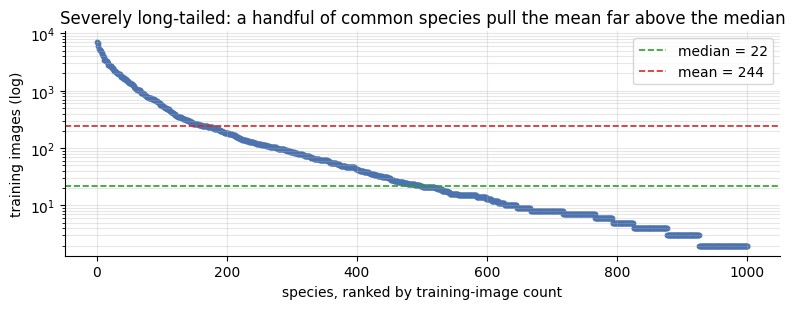

In [2]:
all_rows = load_metadata()
train_rows = rows_for_split(all_rows, "train")
val_rows = rows_for_split(all_rows, "val")
test_rows = rows_for_split(all_rows, "test")
train_counts = images_per_species(train_rows)

print(f"train: {len(train_rows):,}   val: {len(val_rows):,}   test: {len(test_rows):,}   species: {len(train_counts)}")

counts = pd.Series(train_counts).sort_values(ascending=False)
median_count = counts.median()
mean_count = counts.mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(np.arange(1, len(counts) + 1), counts.values, color="#4c72b0", s=10)
ax.axhline(median_count, color="#2ca02c", linestyle="--", linewidth=1.2,
           label=f"median = {median_count:.0f}")
ax.axhline(mean_count, color="#d62728", linestyle="--", linewidth=1.2,
           label=f"mean = {mean_count:.0f}")
ax.set_yscale("log")
ax.set_xlabel("species, ranked by training-image count")
ax.set_ylabel("training images (log)")
ax.set_title("Severely long-tailed: a handful of common species pull the mean far above the median")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Toxicity data - scraped from [ASPCA's cat-toxic-plant pages](https://www.aspca.org/pet-care/animal-poison-control/cats-plant-list)**:
982 pages (`data/raw/aspca/cats_plant_details.json`), a first draft -
never verified, never used as the shipped toxicity table directly
(`aspca_detail.py`). Deduplicated by scientific name into
`data/toxicity.json` (`toxicity_seed.py`) - every entry starts
`"verified": false"` and gets hand-checked one at a time.

In [3]:
toxicity_table = load_table(TOXICITY_TABLE_PATH)
species_rows = load_species_rows()
toxicity_matches = match_against_toxicity_table(species_rows, toxicity_table)

n_verified = sum(1 for e in toxicity_table if e.verified)
n_exact = sum(1 for r in toxicity_matches.values() if r.status == "exact")
n_genus = sum(1 for r in toxicity_matches.values() if r.status == "genus_only")
n_exact_verified = sum(
    1 for r in toxicity_matches.values()
    if r.status == "exact" and r.exact_row.verified
)

aspca_pages = json.loads(ASPCA_DETAILS_JSON_PATH.read_text(encoding="utf-8"))["plants"]

print(f"ASPCA pages scraped:        {len(aspca_pages)}")
print(f"toxicity.json entries:      {len(toxicity_table)}  (deduplicated by scientific name)")
print(f"  of which verified:        {n_verified} / {len(toxicity_table)}")
print()
print(f"PlantNet species w/ EXACT toxicity-table match:  {n_exact} / {len(species_rows)}")
print(f"  of which verified:                             {n_exact_verified} / {n_exact}")
print(f"PlantNet species w/ GENUS-level match only:       {n_genus} / {len(species_rows)}")

ASPCA pages scraped:        982
toxicity.json entries:      571  (deduplicated by scientific name)
  of which verified:        85 / 571

PlantNet species w/ EXACT toxicity-table match:  34 / 1000
  of which verified:                             34 / 34
PlantNet species w/ GENUS-level match only:       240 / 1000


## What makes this hard

1. **Class imbalance.** Median training images/species: 21. Mean: 244.
   Almost half the species (477/1000) have under 20 training images -
   see the chart above and `01_plantnet_class_distribution.ipynb` for
   the full picture.
2. **Toxicity verification is a manual bottleneck, by design.** The
   table above is the live count - it will only grow as entries get
   hand-checked against ASPCA (one at a time, on purpose: no shortcut
   is allowed to produce a `verified: true` entry).
3. **The safety-first rule shapes everything downstream.** A low-data
   species being hard to classify is not just an accuracy problem here
   - it also means the system is *more likely to default to caution*
   (correctly conservative), not more likely to be wrong in a dangerous
   direction. That trade-off (being right vs. being usefully decisive)
   is part of what "good" looks like for this project, not just top-1
   accuracy.

## Roadmap & status

| Phase | What | Status |
|---|---|---|
| 1 | PlantNet-300K baseline (ResNet-18, paper-replica) | ✅ Done - see notebook 03 |
| 2 | Decoupled classifier-head retraining (frozen backbone, Kang et al. 2020) - Class-Balanced loss and Balanced Softmax explored but NOT adopted (see notebook 04): both trade real accuracy for rare-species gains, and turned out unnecessary for Phase 3's result below | ✅ Done - see notebook 04 |
| 3 | Toxicity-aware cost term, added to the same decoupled head | ✅ Done - cuts toxic/non-toxic confusion ~30% relative (0.91% -> 0.63% val) at no further accuracy cost - see notebook 04 |
| 4 | Real `check` command (`PlantNetClassifier` + `pipeline.check_image`) | ✅ Done - `python -m plant_toxicity_checker check --image <path>` |

## Key metrics (the ones we'll report at the end)

Standard ML numbers tell only part of the story for a *toxicity
checker* specifically - see the discussion that led to this list.
`TBD` below is literal: nothing is estimated or guessed ahead of
actually running it.

In [4]:
def load_eval_json(run, filename):
    path = REPO_ROOT / "outputs" / run / filename
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


baseline_val = load_eval_json("plantnet-baseline", "eval_from_features_val.json")
baseline_test = load_eval_json("plantnet-baseline", "eval_from_features_test.json")
baseline_breakdown = load_eval_json("plantnet-baseline", "species_breakdown_val.json")
baseline_tiers = load_eval_json("plantnet-baseline", "verdict_tiers_val.json")

# "Decoupled, no toxicity term" = the same decoupled head, plain CE, no
# imbalance reweighting and no toxicity term - isolates decoupling's own
# cost from the toxicity term's effect below. NOT a shipped model - Class-
# Balanced loss/Balanced Softmax were explored (notebook 04) and neither
# was adopted, so there is no separate "Phase 2 product" to report here.
control_val = load_eval_json("decoupled_ce", "eval_val.json")
control_test = load_eval_json("decoupled_ce", "eval_test.json")
control_breakdown = load_eval_json("decoupled_ce", "species_breakdown_val.json")
control_tiers = load_eval_json("decoupled_ce", "verdict_tiers_val.json")

# "Decoupled + toxicity term" = the recommended model from notebook 04's
# round 5: plain CE + toxicity_cost_weight=20 (no CB-loss/Balanced Softmax
# needed). This is the model `check` actually uses by default (see
# plant_toxicity_checker/config.py's DEFAULT_HEAD_RUN) - the shipped one.
shipped_val = load_eval_json("decoupled_ce_toxicity_w20.0", "eval_val.json")
shipped_test = load_eval_json("decoupled_ce_toxicity_w20.0", "eval_test.json")
shipped_breakdown = load_eval_json("decoupled_ce_toxicity_w20.0", "species_breakdown_val.json")
shipped_tiers = load_eval_json("decoupled_ce_toxicity_w20.0", "verdict_tiers_val.json")


def pct(result, key):
    return f"{result[key]:.1%}" if result else TBD


def bucket_acc(breakdown, name, key):
    if not breakdown:
        return TBD
    value = breakdown["buckets"][name][key]
    return f"{value:.1%}" if value is not None else TBD


def confusion(result):
    if not result:
        return TBD
    rate = result["toxic_confusion"]["confusion_rate"]
    return f"{rate:.2%}" if rate is not None else TBD


def test_summary(result):
    if not result:
        return TBD
    return f"{result['top_1']:.1%} / {result['top_5']:.1%} / {result['avg_5']:.1%}"


def tier_summary(result):
    if not result:
        return TBD
    tiers = result["tiers"]
    order = ["toxic", "caution", "likely_safe"]
    return " / ".join(f"{tiers.get(t, 0.0):.1%}" for t in order)


def exact_match_top1(breakdown):
    """top-1 restricted to the species with an EXACT toxicity-table
    match (34 species, toxic or non-toxic) - same join as notebook
    03's toxicity-category breakdown (`toxicity_matches`, already
    built above), just filtered to "exact" instead of split by
    category."""
    if not breakdown:
        return TBD
    correct = total = 0
    for row in breakdown["species"]:
        if toxicity_matches[row["species_id"]].status != "exact":
            continue
        total += row["n_eval"]
        correct += round(row["top1_accuracy"] * row["n_eval"])
    return f"{correct / total:.1%}" if total else TBD


rows = [
    ("val top-1 (species ID)",
     pct(baseline_val, "top_1"), pct(control_val, "top_1"), pct(shipped_val, "top_1")),
    ("val top-5 (species ID)",
     pct(baseline_val, "top_5"), pct(control_val, "top_5"), pct(shipped_val, "top_5")),
    ("test top-1 / top-5 / avg-5 (paper's own metric)",
     test_summary(baseline_test), test_summary(control_test), test_summary(shipped_test)),
    ("top-1 on species w/ <20 train images",
     bucket_acc(baseline_breakdown, "<20", "top1_accuracy"),
     bucket_acc(control_breakdown, "<20", "top1_accuracy"),
     bucket_acc(shipped_breakdown, "<20", "top1_accuracy")),
    ("top-1 on species w/ 200+ train images",
     bucket_acc(baseline_breakdown, "200+", "top1_accuracy"),
     bucket_acc(control_breakdown, "200+", "top1_accuracy"),
     bucket_acc(shipped_breakdown, "200+", "top1_accuracy")),
    ("toxic/non-toxic confusion rate (val, known-side species)",
     confusion(baseline_val), confusion(control_val), confusion(shipped_val)),
    ("top-1 on EXACT toxicity-table matches (34 species)",
     exact_match_top1(baseline_breakdown),
     exact_match_top1(control_breakdown),
     exact_match_top1(shipped_breakdown)),
    ("toxicity-table coverage (verified / exact-matched species)",
     f"{n_exact_verified}/{n_exact}", f"{n_exact_verified}/{n_exact}", f"{n_exact_verified}/{n_exact}"),
    ("verdict-tier coverage (% TOXIC / CAUTION / LIKELY_SAFE)",
     tier_summary(baseline_tiers), tier_summary(control_tiers), tier_summary(shipped_tiers)),
    ("false-LIKELY_SAFE rate on known-toxic species",
     "0% (structural guarantee - see tests/test_verdict.py, not measured empirically)",
     "same guarantee", "same guarantee"),
]
pd.DataFrame(rows, columns=["metric", 'Phase 1 (baseline, jointly-trained)', 'Decoupled, no toxicity term (control)', 'Decoupled + toxicity term (shipped)']).set_index("metric")

,"Phase 1 (baseline, jointly-trained)","Decoupled, no toxicity term (control)",Decoupled + toxicity term (shipped)
metric,,,
val top-1 (species ID),81.2%,80.5%,80.4%
val top-5 (species ID),95.6%,95.1%,95.0%
test top-1 / top-5 / avg-5 (paper's own metric),81.4% / 95.8% / 97.3%,80.6% / 95.4% / 96.8%,80.5% / 95.2% / 96.7%
top-1 on species w/ <20 train images,13.1%,14.6%,14.9%
top-1 on species w/ 200+ train images,86.1%,85.3%,85.3%
"toxic/non-toxic confusion rate (val, known-side species)",0.90%,0.91%,0.63%
top-1 on EXACT toxicity-table matches (34 species),88.8%,88.4%,88.3%
toxicity-table coverage (verified / exact-matched species),34/34,34/34,34/34
verdict-tier coverage (% TOXIC / CAUTION / LIKELY_SAFE),6.1% / 84.9% / 8.9%,6.2% / 84.4% / 9.5%,6.1% / 84.4% / 9.6%


**Reading the table**: the columns are named for what they
actually are, not for roadmap phase numbers - "control" and "shipped"
rather than bare "Phase 2"/"Phase 3", since Class-Balanced loss and
Balanced Softmax (notebook 04) were explored but NOT adopted. There is
no separate "Phase 2 product" to report; the control column exists
only to isolate decoupling's own cost from the toxicity term's effect.

The species-ID rows (top-1/top-5/avg-5, and the data-volume splits)
did NOT improve control -> shipped - decoupling alone (control) costs
~0.7 points of top-1 against the baseline, and adding the toxicity
term (shipped) costs nothing further. That is by design, not a
regression: the control column's job was ruling out whether imbalance
reweighting was worth its own real accuracy cost - it wasn't needed -
and the shipped column's job was the confusion-rate row specifically,
which DID move (0.91% -> 0.63%, about a 30% relative cut) while
leaving accuracy untouched. A flat accuracy row and a moving
confusion-rate row together are the success case here, not a sign
nothing changed. The toxicity-table coverage and false-LIKELY_SAFE
rows aren't model metrics at all: coverage only grows as entries get
hand-verified (same number across all three columns until that work
finishes), and the false-safe rate is a property of `verdict.py`'s
code, not of which model is plugged in - it doesn't improve with a
better classifier, it's just true or it isn't.

**The verdict-tier coverage row** - Phase 4's real classifier
(`PlantNetClassifier`, via `decoupled.verdict_tier_coverage`) made it
measurable for the first time, over the full val split (31,115
images). It barely moves either, which is the expected result:
CAUTION dominates (~84-85%) because most PlantNet species have no
toxicity-table entry at all (726 of 1,000 - see the CAUTION breakdown
below) regardless of which model is plugged in - this row mostly
reflects the table's coverage, not the classifier's accuracy. TOXIC
sits at ~6%, LIKELY_SAFE at ~9%.

**The EXACT toxicity-table matches row** - restricted to the 34
species with an exact match, same join notebook 03 used for its
toxicity-category breakdown (`toxicity_matches`, built above). Also
fairly flat (88.8% -> 88.3%) - consistent with the toxicity term
targeting the CONFUSION rate specifically, not overall accuracy on
these species.

## Accuracy vs. how much training data a species had

Notebook 03's version of this chart only had the baseline to show.
Same bucket breakdown, same reasoning (the headline top-1 number
hides a severe split by training-image count) - now with the two
retrained models from the table above alongside it, so the "flat
accuracy, moving confusion" finding is visible, not just stated.

In [5]:
BUCKET_ORDER = ["<20", "20-49", "50-199", "200+"]
BUCKET_MODELS = [
    ("Baseline", baseline_breakdown),
    ("Control", control_breakdown),
    ("Shipped", shipped_breakdown),
]

bucket_comparison_df = pd.DataFrame({
    f"{label} top-{k}": [
        breakdown["buckets"][b][f"top{k}_accuracy"] for b in BUCKET_ORDER
    ]
    for label, breakdown in BUCKET_MODELS
    for k in (1, 5)
}, index=BUCKET_ORDER)
bucket_comparison_df

,Baseline top-1,Baseline top-5,Control top-1,Control top-5,Shipped top-1,Shipped top-5
<20,0.130986,0.473239,0.146479,0.502817,0.149296,0.497183
20-49,0.374069,0.791356,0.366617,0.779434,0.368107,0.773472
50-199,0.596561,0.906038,0.579768,0.892443,0.579768,0.892043
200+,0.860684,0.977087,0.853266,0.972019,0.852715,0.971138


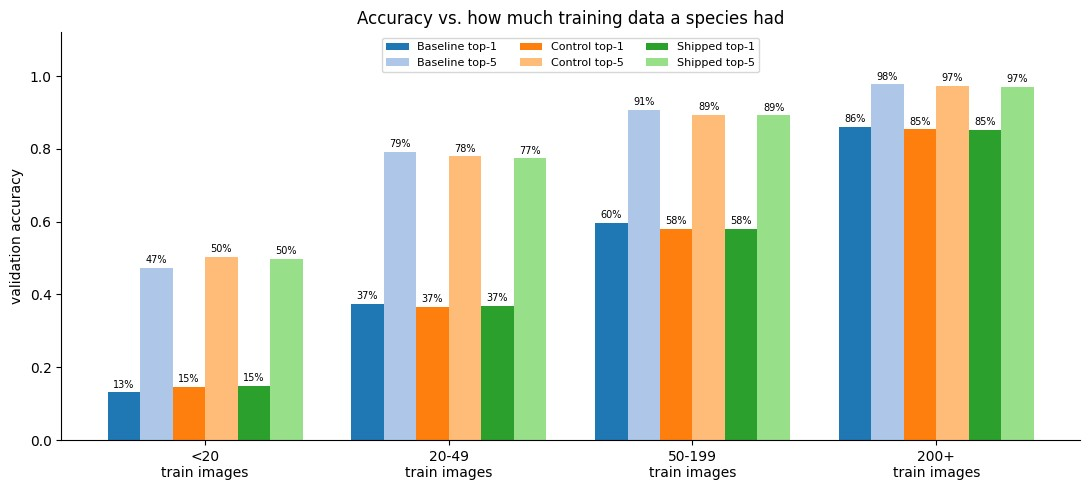

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(BUCKET_ORDER))
n_models = len(BUCKET_MODELS)
model_width = 0.8 / n_models
bar_width = model_width / 2
tab20 = plt.cm.tab20.colors  # (dark, light) pairs per hue: blue, orange, green, ...

for m, (label, breakdown) in enumerate(BUCKET_MODELS):
    top1 = [breakdown["buckets"][b]["top1_accuracy"] for b in BUCKET_ORDER]
    top5 = [breakdown["buckets"][b]["top5_accuracy"] for b in BUCKET_ORDER]
    center = x + (m - (n_models - 1) / 2) * model_width
    dark, light = tab20[2 * m], tab20[2 * m + 1]

    bars1 = ax.bar(center - bar_width / 2, top1, bar_width, color=dark, label=f"{label} top-1")
    bars5 = ax.bar(center + bar_width / 2, top5, bar_width, color=light, label=f"{label} top-5")
    ax.bar_label(bars1, labels=[f"{v:.0%}" for v in top1], fontsize=7, padding=2)
    ax.bar_label(bars5, labels=[f"{v:.0%}" for v in top5], fontsize=7, padding=2)

ax.set_xticks(x)
ax.set_xticklabels([f"{b}\ntrain images" for b in BUCKET_ORDER])
ax.set_ylabel("validation accuracy")
ax.set_ylim(0, 1.12)
ax.set_title("Accuracy vs. how much training data a species had")
ax.legend(fontsize=8, ncol=3, loc="upper center")
plt.tight_layout()
plt.show()

Rare species (`<20` images) gain a few points from decoupling
alone, and the toxicity term doesn't change that redistribution
either way - the same "flat overall, shifted underneath" pattern the
Key Metrics table's rows already showed, just visible per bucket now
instead of only at the two extremes.

## The verdict logic, demonstrated

What *can* already be shown, without a real classifier: `verdict.py`
now does genus-fallback matching against `data/toxicity.json`
(`species_match.lookup_toxicity`/`toxicity_category`) instead of a
plain exact-name lookup - a species with no exact entry falls back to
its genus, with a toxic signal from a genus-level placeholder (ASPCA's
own genus-wide claim) treated as confidently as an exact match, a
signal from only a specific relative capped at caution, and neither
ever able to produce `LIKELY_SAFE`.

Not the same thing as the empirical "verdict-tier coverage" row above
(that needs real photos) - this is the **ceiling**: if every one of
PlantNet's 1,000 species were identified with perfect confidence and
nothing else, what would `assess()` say for each one, today, given how
much of the toxicity table is verified so far.

In [7]:
import collections

species_names = [row["full_species"] for row in load_species_rows()]
verdict_counts = collections.Counter()
for name in species_names:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    verdict_counts[v.status] += 1

ceiling_df = pd.DataFrame(
    {"species": [verdict_counts[s] for s in Status]},
    index=[s.value for s in Status],
)
ceiling_df["share"] = (ceiling_df["species"] / len(species_names)).map("{:.1%}".format)
ceiling_df

,species,share
toxic,39,3.9%
caution,933,93.3%
likely_safe,28,2.8%


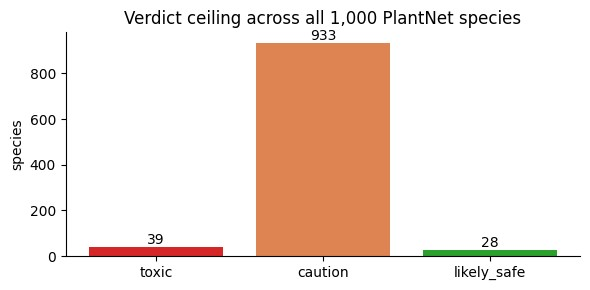

Confirmed: every LIKELY_SAFE verdict above has an exact, verified non-toxic entry.


In [8]:
fig, ax = plt.subplots(figsize=(6, 3))
colors = {"toxic": "#d62728", "caution": "#dd8452", "likely_safe": "#2ca02c"}
ax.bar(ceiling_df.index, ceiling_df["species"], color=[colors[s] for s in ceiling_df.index])
ax.set_ylabel("species")
ax.set_title("Verdict ceiling across all 1,000 PlantNet species")
for i, status in enumerate(ceiling_df.index):
    ax.text(i, ceiling_df["species"][status], str(ceiling_df["species"][status]), ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Structural guarantee, checked here rather than just asserted: every
# LIKELY_SAFE verdict above really does rest on an exact, verified
# non-toxic entry - never a genus-level inference.
for name in species_names:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    if v.status is Status.LIKELY_SAFE:
        assert v.entry is not None and v.entry.verified and v.entry.toxic_to_cats == "no"
print("Confirmed: every LIKELY_SAFE verdict above has an exact, verified non-toxic entry.")

**`CAUTION` isn't one thing.** 933 species land there, but for
different reasons - a species whose genus has a known-toxic relative
is a very different kind of "we're not sure" than a species the
toxicity table has nothing at all to say about. Splitting it by the
underlying match category (the same ``toxicity_category`` used above):

In [9]:
toxicity_index = build_toxicity_index(toxicity_table)
caution_reasons = collections.Counter()
for name in species_names:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    if v.status is Status.CAUTION:
        caution_reasons[toxicity_category(lookup_toxicity(name, toxicity_index))] += 1

CAUTION_LABELS = {
    "genus - toxic (inferred)": "toxic relative in the genus",
    "genus - non-toxic (direct)": "genus page itself says non-toxic",
    "genus - non-toxic (inferred)": "non-toxic relative in the genus",
    "no match": "nothing in the table at all",
}
caution_df = pd.DataFrame(
    {"species": [caution_reasons.get(cat, 0) for cat in CAUTION_LABELS]},
    index=[CAUTION_LABELS[cat] for cat in CAUTION_LABELS],
)
caution_df["share of all CAUTION"] = (caution_df["species"] / caution_df["species"].sum()).map("{:.1%}".format)
caution_df

,species,share of all CAUTION
toxic relative in the genus,72,7.7%
genus page itself says non-toxic,23,2.5%
non-toxic relative in the genus,112,12.0%
nothing in the table at all,726,77.8%


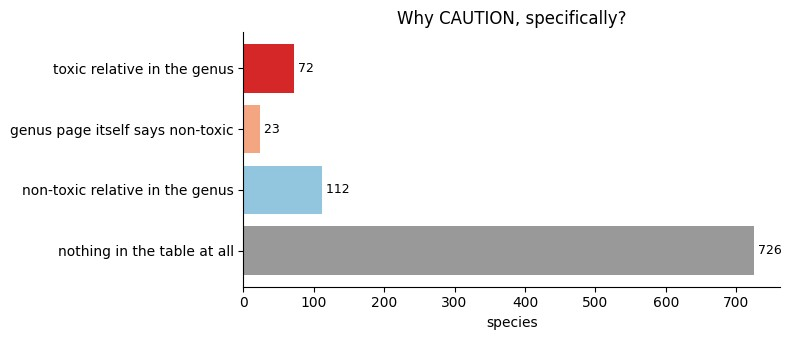

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ["#d62728", "#f4a582", "#92c5de", "#999999"]
ax.barh(caution_df.index, caution_df["species"], color=colors)
ax.invert_yaxis()
ax.set_xlabel("species")
ax.set_title("Why CAUTION, specifically?")
for i, n in enumerate(caution_df["species"]):
    ax.text(n, i, f" {n}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

Only 72 of the 933 are "a specific relative is toxic" - the
`Tradescantia fluminensis` case below. The other 861 are species the
table either says nothing about at all (726), or where a relative
points *towards* safety but can't structurally be trusted to confirm
it (135 - the genus-level non-toxic signal that, by design, can never
promote to `LIKELY_SAFE`). That second group is arguably the most
promising place for future verification effort: unlike "no match", it
already has *some* real signal.

## How every species gets its side for the toxicity cost term

The CAUTION/TOXIC/LIKELY_SAFE split above is the **verdict** path - strict,
verified-only where it matters. Phase 3's training-time toxicity cost term
(`decoupled.toxicity_cost_term`, see notebook 04) uses a looser, binary
version of the same underlying match data (`toxicity_category`), allowed
to draw on unverified and genus-inferred signal since it only shapes a
loss term, never the real safety verdict. The decision tree below is the
exact logic `species_match.toxicity_side` applies to every one of the
1,000 PlantNet species - leaves colored by the side the cost term actually
uses: **red = toxic**, **blue = non-toxic**, **gray = excluded** (no
signal at all, side `-1`).

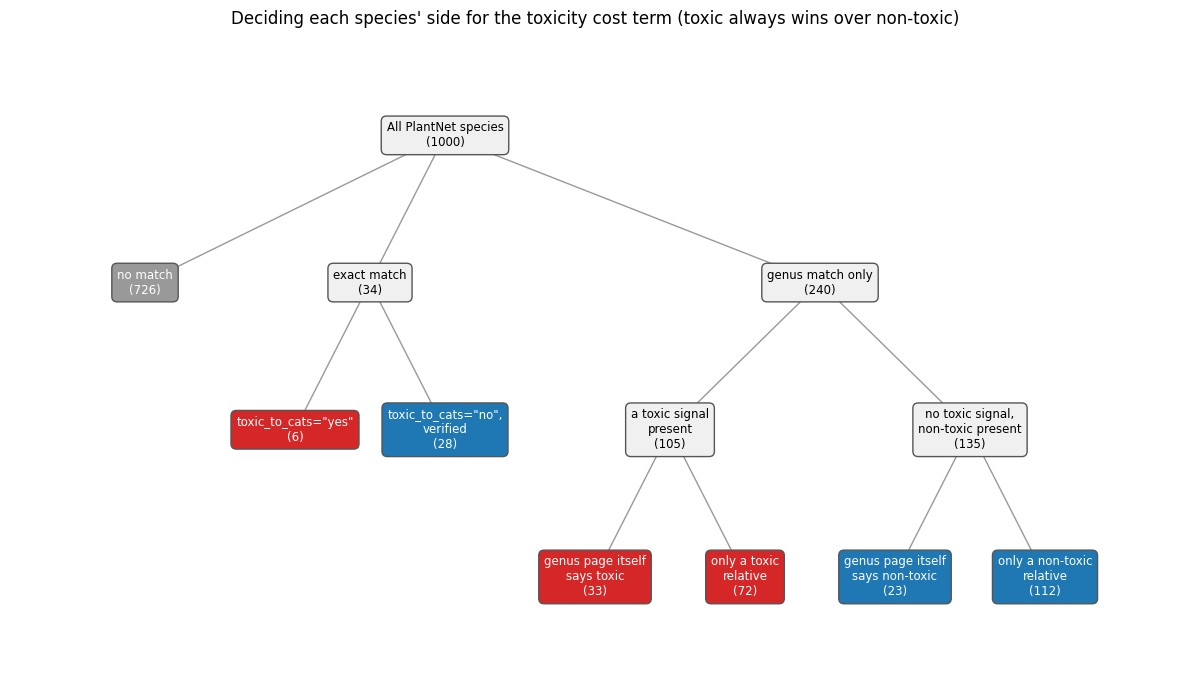

In [11]:
import collections

cat_counts = collections.Counter(
    toxicity_category(result) for result in toxicity_matches.values()
)

RED, BLUE, GRAY, NEUTRAL = "#d62728", "#1f77b4", "#999999", "#f0f0f0"

# (x, y, category key or None for a non-leaf decision node, label prefix,
# face color, text color) - y = depth from the root (4); x hand-placed so
# each parent sits above the mean of its children (a real tree layout).
tree_nodes = {
    "root": (2.0, 4, None, "All PlantNet species", NEUTRAL, "black"),
    "nomatch": (0.0, 3, "no match", "no match", GRAY, "white"),
    "exact": (1.5, 3, None, "exact match", NEUTRAL, "black"),
    "genus": (4.5, 3, None, "genus match only", NEUTRAL, "black"),
    "exact_toxic": (1.0, 2, "exact - toxic", 'toxic_to_cats="yes"', RED, "white"),
    "exact_nontoxic": (2.0, 2, "exact - non-toxic", 'toxic_to_cats="no",\nverified', BLUE, "white"),
    "genus_toxicsig": (3.5, 2, None, "a toxic signal\npresent", NEUTRAL, "black"),
    "genus_nontoxicsig": (5.5, 2, None, "no toxic signal,\nnon-toxic present", NEUTRAL, "black"),
    "genus_toxic_direct": (3.0, 1, "genus - toxic (direct)", "genus page itself\nsays toxic", RED, "white"),
    "genus_toxic_inferred": (4.0, 1, "genus - toxic (inferred)", "only a toxic\nrelative", RED, "white"),
    "genus_nontoxic_direct": (5.0, 1, "genus - non-toxic (direct)", "genus page itself\nsays non-toxic", BLUE, "white"),
    "genus_nontoxic_inferred": (6.0, 1, "genus - non-toxic (inferred)", "only a non-toxic\nrelative", BLUE, "white"),
}
# Non-leaf decision nodes show the sum of everything beneath them.
non_leaf_totals = {
    "exact": cat_counts["exact - toxic"] + cat_counts["exact - non-toxic"],
    "genus_toxicsig": cat_counts["genus - toxic (direct)"] + cat_counts["genus - toxic (inferred)"],
    "genus_nontoxicsig": cat_counts["genus - non-toxic (direct)"] + cat_counts["genus - non-toxic (inferred)"],
}
non_leaf_totals["genus"] = non_leaf_totals["genus_toxicsig"] + non_leaf_totals["genus_nontoxicsig"]
non_leaf_totals["root"] = len(toxicity_matches)

tree_edges = [
    ("root", "nomatch"), ("root", "exact"), ("root", "genus"),
    ("exact", "exact_toxic"), ("exact", "exact_nontoxic"),
    ("genus", "genus_toxicsig"), ("genus", "genus_nontoxicsig"),
    ("genus_toxicsig", "genus_toxic_direct"), ("genus_toxicsig", "genus_toxic_inferred"),
    ("genus_nontoxicsig", "genus_nontoxic_direct"), ("genus_nontoxicsig", "genus_nontoxic_inferred"),
]

fig, ax = plt.subplots(figsize=(12, 7))
for a, b in tree_edges:
    xa, ya = tree_nodes[a][:2]
    xb, yb = tree_nodes[b][:2]
    ax.plot([xa, xb], [ya, yb], color="#999999", linewidth=1, zorder=1)
for key, (x, y, cat, prefix, face, text_color) in tree_nodes.items():
    n = cat_counts[cat] if cat is not None else non_leaf_totals[key]
    ax.annotate(
        f"{prefix}\n({n})", (x, y), ha="center", va="center", fontsize=8.5,
        color=text_color,
        bbox=dict(boxstyle="round,pad=0.45", facecolor=face, edgecolor="#555555"),
        zorder=2,
    )
ax.set_xlim(-0.9, 6.9)
ax.set_ylim(0.3, 4.7)
ax.axis("off")
ax.set_title("Deciding each species' side for the toxicity cost term (toxic always wins over non-toxic)")
plt.tight_layout()
plt.show()

The tree's 7 leaf categories collapse to exactly the 3 groups the cost
term's math actually operates on - `species_match.toxicity_side` throws
away the direct/inferred distinction entirely (it's about how confident
the *label* is, not something the loss needs to weight differently):

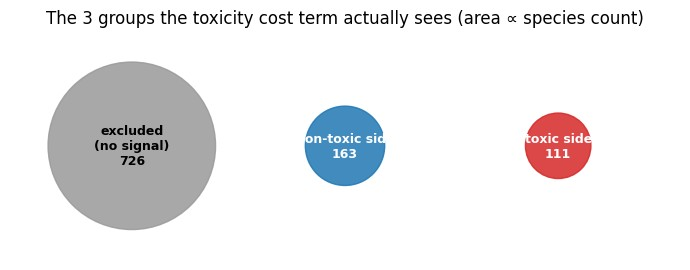

In [12]:
from plant_toxicity_checker.species_match import toxicity_side

side_counts = collections.Counter(
    toxicity_side(result) for result in toxicity_matches.values()
)
SIDE_GROUPS = [
    ("excluded\n(no signal)", None, GRAY),
    ("non-toxic side", "non_toxic", BLUE),
    ("toxic side", "toxic", RED),
]

fig, ax = plt.subplots(figsize=(7, 4))
max_n = max(side_counts[key] for _, key, _ in SIDE_GROUPS)
for i, (label, key, color) in enumerate(SIDE_GROUPS):
    n = side_counts[key]
    radius = 0.55 * (n / max_n) ** 0.5  # area, not radius, proportional to count
    ax.add_patch(plt.Circle((i * 1.4, 0), radius, color=color, alpha=0.85))
    ax.annotate(
        f"{label}\n{n}", (i * 1.4, 0), ha="center", va="center",
        fontsize=9, color="black" if color == GRAY else "white", fontweight="bold",
    )
ax.set_xlim(-0.8, 1.4 * (len(SIDE_GROUPS) - 1) + 0.8)
ax.set_ylim(-0.75, 0.75)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("The 3 groups the toxicity cost term actually sees (area ∝ species count)")
plt.tight_layout()
plt.show()

**Worth remembering when reading `toxic_confusion_rate` numbers**:
roughly two-thirds of the signal behind them (184 of 274 non-excluded
species) comes from an *inferred* sibling relationship, not a verified
ASPCA entry - a real, intentional gap between this training-time signal
and the much stricter standard the `check` command's actual verdict
requires.

A real example of each path the matching logic can take, reason
text and all - this is exactly what a real `check` command would show
a user. Four genuinely different PlantNet species, chosen to exercise
each case (not just the first one found):

- an **exact** match (`Hypericum perforatum` is itself in the table)
- a **genus - direct** match (`Pelargonium capitatum` isn't in the
  table, but ASPCA's own genus-wide `"Pelargonium species"` page is)
- a **genus - inferred** match (`Tradescantia fluminensis` isn't in
  the table and there's no genus placeholder either - only a
  *specific*, different relative, `tradescantia multiflora`, happens
  to be toxic)
- an **exact, verified non-toxic** match (`Nephrolepis exaltata` -
  the only kind of match that can ever reach `LIKELY_SAFE`)

In [13]:
demo_species = [
    "Hypericum perforatum L.",
    "Pelargonium capitatum (L.) L'Hér.",
    "Tradescantia fluminensis Vell.",
    "Nephrolepis exaltata (L.) Schott",
]
for name in demo_species:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    print(f"{v.status.value:>12}: {name}")
    for reason in v.reasons:
        print(f"             {reason}")
    print()

       toxic: Hypericum perforatum L.
             Best match 'Hypericum perforatum L.' is toxic to cats.

       toxic: Pelargonium capitatum (L.) L'Hér.
             Best match 'Pelargonium capitatum (L.) L'Hér.' is in a genus ASPCA lists as toxic to cats.

     caution: Tradescantia fluminensis Vell.
             'Tradescantia fluminensis Vell.' is not itself in the toxicity table, but a relative, 'Tradescantia flumeninsis', is toxic to cats; treat as toxic.

 likely_safe: Nephrolepis exaltata (L.) Schott
             'Nephrolepis exaltata (L.) Schott' is verified non-toxic to cats and the match is confident. Still check with a vet if a cat ate any.



## The real check command (Phase 4)

The section above used hypothetical 100%-confidence predictions,
because there was no real classifier yet. Now there is
(`PlantNetClassifier`, Phase 4 - see `notebooks/04_decoupled_training_
comparison.ipynb` for how its model was chosen) - the exact same
`Hypericum perforatum` example above, but this time a real photo, a
real (imperfect) confidence, and the real `python -m
plant_toxicity_checker check` CLI underneath this call.

In [14]:
from plant_toxicity_checker.config import (
    DEFAULT_BACKBONE_RUN,
    DEFAULT_HEAD_RUN,
    PLANTNET_DIR,
)
from plant_toxicity_checker.pipeline import check_image
from plant_toxicity_checker.plantnet_classifier import PlantNetClassifier

real_classifier_path = REPO_ROOT / "checkpoints" / DEFAULT_HEAD_RUN / "head.pt"
if not real_classifier_path.exists():
    print(f"pending - no checkpoint at {real_classifier_path} (pull it "
          f"from the remote PC with scripts/remote/pull.sh checkpoints)")
else:
    classifier = PlantNetClassifier(DEFAULT_BACKBONE_RUN, DEFAULT_HEAD_RUN)
    real_photo = (
        PLANTNET_DIR / "images" / "val" / "0011"
        / "000ccbc3d460fe584a715f0f52647450b83e5823.jpg"
    )
    verdict = check_image(real_photo, classifier, toxicity_table)
    print(f"{verdict.status.value:>12}: {verdict.species} ({verdict.confidence:.1%})")
    for reason in verdict.reasons:
        print(f"             {reason}")

       toxic: Hypericum perforatum L. (99.7%)
             Best match 'Hypericum perforatum L.' is toxic to cats.


## Next up

- Decide whether the moderate-cost candidate from notebook 04 (more
  toxicity weight, more accuracy spent) is worth pursuing further - it
  needs a couple more seeds before trusting a specific number, and isn't
  needed unless the zero-cost pick above turns out not to be enough.
- Re-run this notebook whenever something changes - that's the point.